<a href="https://colab.research.google.com/github/RIZ4N/BigData26_B_2411531010_RizanOesvanIdrati/blob/main/Praktikum5/BD_P05_2411531010_Rizan_Oesvan_Idrati.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# BD_P05: Pipeline Data Berita — dari Ingestion hingga MapReduce
Rizan Oesvan Idrati — 2411531010
```

# BD_P05: Pipeline Data Berita — dari Ingestion hingga MapReduce
Rizan Oesvan Idrati — 2411531010

```markdown
## Persiapan: memasang pustaka
```

## Persiapan: memasang pustaka

```markdown
Berikut adalah proses instalasi library Python yang diperlukan untuk analisis data, web scraping, dan database lokal (DuckDB).
```

In [1]:
!pip install -q duckdb beautifulsoup4 lxml requests pyarrow pandas

```markdown
## H-1. Peta Pipeline dan Permainan Kartu Kantin
Bagian ini dikerjakan tanpa laptop (permainan kartu). Hasil yang harus didapat: nasi goreng 5, es teh 8, mie ayam 4.
Catat jumlah kartu yang berpindah meja tanpa dan dengan combiner; angkanya dicocokkan dengan kode pada H-8.
```

## H-1. Peta Pipeline dan Permainan Kartu Kantin
Bagian ini dikerjakan tanpa laptop (permainan kartu). Hasil yang harus didapat: nasi goreng 5, es teh 8, mie ayam 4.
Catat jumlah kartu yang berpindah meja tanpa dan dengan combiner; angkanya dicocokkan dengan kode pada H-8.

```markdown
## H-2. Persiapan: Unduh Data dan Jalankan Portal Lokal
```

## H-2. Persiapan: Unduh Data dan Jalankan Portal Lokal

```markdown
Langkah ini bertujuan mengunduh dataset berita Detik dari repositori GitHub eksternal jika berkas belum tersedia di lokal, lalu membacanya menggunakan pandas.
```

In [2]:
import os, re, json, time, zlib, queue, threading, collections
from pathlib import Path
import urllib.request
import pandas as pd

URL_DATA = ("https://raw.githubusercontent.com/ibamibrahim/"
            "dataset-judul-berita-indonesia/master/detik_news_title.csv")
if not os.path.exists("detik_news_title.csv"):
    urllib.request.urlretrieve(URL_DATA, "detik_news_title.csv")

df_sumber = pd.read_csv("detik_news_title.csv")
print("Ukuran berkas :", round(os.path.getsize("detik_news_title.csv") / 1e6, 1), "MB")
print("Baris, kolom  :", df_sumber.shape)
print("Kolom         :", list(df_sumber.columns))

Ukuran berkas : 16.1 MB
Baris, kolom  : (91017, 4)
Kolom         : ['date', 'url', 'title', 'category']


```markdown
Kode di bawah ini berfungsi untuk menjalankan server HTTP lokal secara background (threading) guna menyimulasikan situs web portal berita untuk proses crawling.
```

In [3]:
import http.server, urllib.parse, html

HALAMAN_UKURAN = 100               # judul per halaman

def jalankan_portal(df, port=8000):
    """Portal berita lokal (siap pakai): menyajikan judul dalam halaman HTML."""
    baris = df.to_dict("records")
    n_hal = (len(baris) + HALAMAN_UKURAN - 1) // HALAMAN_UKURAN

    class Handler(http.server.BaseHTTPRequestHandler):
        def log_message(self, *args):            # matikan log
            pass
        def _kirim(self, kode, teks, tipe="text/html; charset=utf-8"):
            data = teks.encode("utf-8")
            self.send_response(kode)
            self.send_header("Content-Type", tipe)
            self.send_header("Content-Length", str(len(data)))
            self.end_headers()
            self.wfile.write(data)
        def do_GET(self):
            u = urllib.parse.urlparse(self.path)
            if u.path == "/robots.txt":
                self._kirim(200, "User-agent: *\nDisallow: /arsip-privat/\n", "text/plain")
            elif u.path == "/arsip-privat/":
                self._kirim(200, "<p>Halaman ini tidak boleh di-crawl.</p>")
            elif u.path == "/berita":
                q = urllib.parse.parse_qs(u.query)
                hal = int(q.get("hal", ["1"])[0])
                if not 1 <= hal <= n_hal:
                    return self._kirim(404, "<p>Halaman tidak ada</p>")
                potong = baris[(hal - 1) * HALAMAN_UKURAN: hal * HALAMAN_UKURAN]
                isi = []
                for r in potong:
                    iso = pd.to_datetime(r["date"], format="%m/%d/%Y").strftime("%Y-%m-%d")
                    isi.append(
                        '<article class="item">'
                        f'<h2 class="judul"><a href="{html.escape(r["url"])}">{html.escape(r["title"])}</a></h2>'
                        f'<span class="kategori">{html.escape(r["category"])}</span>'
                        f'<time datetime="{iso}">{html.escape(r["date"])}</time>'
                        '</article>')
                self._kirim(200, f"<html><body><h1>Portal Contoh</h1>{''.join(isi)}"
                                 f'<nav data-total="{n_hal}"></nav></body></html>')
            else:
                self._kirim(404, "<p>Tidak ditemukan</p>")

    server = http.server.ThreadingHTTPServer(("127.0.0.1", port), Handler)
    threading.Thread(target=server.serve_forever, daemon=True).start()
    return server, n_hal

server, N_HALAMAN = jalankan_portal(df_sumber)
BASE = "http://127.0.0.1:8000"
print("Portal lokal aktif di", BASE, "| jumlah halaman:", N_HALAMAN)

Portal lokal aktif di http://127.0.0.1:8000 | jumlah halaman: 911


```markdown
## H-3. Crawling Portal Lokal: Latihan Aman
```

## H-3. Crawling Portal Lokal: Latihan Aman

```markdown
Kode di bawah ini melakukan pembacaan berkas aturan crawling `robots.txt` pada portal berita lokal yang telah diaktifkan sebelumnya.
```

In [4]:
import requests, urllib.robotparser
from bs4 import BeautifulSoup

UA = "KelasBigData-UNAND/1.0 (praktikum; kontak: dosen)"

def baca_robots(base):
    r = requests.get(base + "/robots.txt", headers={"User-Agent": UA}, timeout=10)
    rp = urllib.robotparser.RobotFileParser()
    rp.parse(r.text.splitlines())
    return rp

robots = baca_robots(BASE)
for jalur in ["/berita?hal=1", "/arsip-privat/"]:
    boleh = robots.can_fetch(UA, BASE + jalur)
    print(f"{jalur:<18} boleh di-crawl? {boleh}")

/berita?hal=1      boleh di-crawl? True
/arsip-privat/     boleh di-crawl? False


```markdown
Fungsi di bawah ini digunakan untuk parsing elemen HTML berita menggunakan BeautifulSoup serta melakukan proses crawling secara iteratif dan sopan (mengikuti robots.txt).
```

In [5]:
def parse_halaman(teks_html):
    """Ubah HTML satu halaman menjadi daftar dict (judul, url, kategori, tanggal)."""
    sup = BeautifulSoup(teks_html, "html.parser")
    hasil = []
    for a in sup.select("article.item"):
        link = a.select_one("h2.judul a")
        hasil.append({
            "judul": link.get_text(strip=True),
            "url": link["href"],
            "kategori": a.select_one("span.kategori").get_text(strip=True),
            "tanggal": a.select_one("time")["datetime"],
        })
    return hasil

def crawl_iter(base, halaman, delay=0.0, ua=UA):
    """Siap pakai: ambil halaman satu per satu, patuhi robots.txt, beri jeda."""
    rp = baca_robots(base)
    sesi = requests.Session()
    sesi.headers["User-Agent"] = ua
    for h in halaman:
        url = f"{base}/berita?hal={h}"
        if not rp.can_fetch(ua, url):
            print("Dilewati (robots.txt):", url)
            continue
        for percobaan in range(3):
            try:
                r = sesi.get(url, timeout=10)
                r.raise_for_status()
                break
            except requests.RequestException as e:
                time.sleep(0.5 * (percobaan + 1))
        else:
            print("Gagal setelah 3 percobaan:", url)
            continue
        yield from parse_halaman(r.text)
        time.sleep(delay)

contoh = list(crawl_iter(BASE, range(1, 4)))
print("Judul dari 3 halaman:", len(contoh))
for c in contoh[:3]:
    print(c)

Judul dari 3 halaman: 300
{'judul': 'Kemnaker Awasi TKA di Meikarta', 'url': 'https://finance.detik.com/berita-ekonomi-bisnis/d-4916114/kemnaker-awasi-tka-di-meikarta', 'kategori': 'finance', 'tanggal': '2020-02-26'}
{'judul': 'BNI Digitalkan BNI Java Jazz 2020', 'url': 'https://finance.detik.com/berita-ekonomi-bisnis/d-4916199/bni-digitalkan-bni-java-jazz-2020', 'kategori': 'finance', 'tanggal': '2020-02-26'}
{'judul': 'Terbang ke Australia, Edhy Prabowo Mau Genjot Budi Daya Lobster', 'url': 'https://finance.detik.com/berita-ekonomi-bisnis/d-4916193/terbang-ke-australia-edhy-prabowo-mau-genjot-budi-daya-lobster', 'kategori': 'finance', 'tanggal': '2020-02-26'}


```markdown
## H-4. Crawling Berita Sungguhan dari Sitemap detik.com
**Langkah 1 — parser sitemap (bagian kunci).**
```

## H-4. Crawling Berita Sungguhan dari Sitemap detik.com
**Langkah 1 — parser sitemap (bagian kunci).**

```markdown
Kode di bawah ini mendefinisikan fungsi parser khusus untuk membaca format sitemap XML milik detik.com untuk mengekstrak informasi detail berita.
```

In [6]:
from bs4 import BeautifulSoup
from urllib.parse import urlparse

POLA_ARTIKEL = re.compile(r"https?://([\w-]+)\.detik\.com/.+/d-(\d+)/")

def parse_sitemap_news(xml_data):
    """Ubah sitemap berita (XML) menjadi daftar dict (judul, url, kategori, id, tanggal, kata_kunci)."""
    sup = BeautifulSoup(xml_data, "xml")
    hasil = []
    for u in sup.find_all("url"):
        loc, judul, waktu = u.find("loc"), u.find("title"), u.find("publication_date")
        if loc is None or judul is None:
            continue
        url = loc.get_text(strip=True)
        m = POLA_ARTIKEL.match(url)
        kunci = u.find("keywords")
        hasil.append({
            "judul": re.sub(r"\s+", " ", judul.get_text(strip=True)),
            "url": url,
            "kategori": m.group(1) if m else urlparse(url).netloc.split(".")[0],   # news, inet, sport, ...
            "id": int(m.group(2)) if m else None,
            "tanggal": waktu.get_text(strip=True)[:10] if waktu else None,
            "kata_kunci": kunci.get_text(strip=True) if kunci else "",
        })
    return hasil

```markdown
**Langkah 2 — uji parser tanpa internet.**
```

**Langkah 2 — uji parser tanpa internet.**

```markdown
Pengujian fungsi parser sitemap menggunakan data XML statis tiruan untuk memastikan parsing tag-tag XML berjalan dengan benar.
```

In [7]:
# Contoh XML: bentuk disalin dari sitemap berita asli (tiga entri hasil uji dosen, 29 Okt 2026).
CONTOH_XML = """<?xml version="1.0" encoding="UTF-8"?>
<urlset xmlns="http://www.sitemaps.org/schemas/sitemap/0.9"
        xmlns:news="http://www.google.com/schemas/sitemap-news/0.9">
  <url>
    <loc><![CDATA[https://news.detik.com/berita/d-8729282/mk-kepala-daerah-terdakwa-politik-tak-bisa-diberhentikan-tanpa-usulan-dprd]]></loc>
    <news:news>
      <news:publication><news:name>detikNews</news:name><news:language>id</news:language></news:publication>
      <news:publication_date>2026-10-29T12:52:00+00:00</news:publication_date>
      <news:title><![CDATA[MK: Kepala Daerah 'Terdakwa Politik' Tak Bisa Diberhentikan Tanpa Usulan DPRD]]></news:title>
      <news:keywords><![CDATA[mahkamah konstitusi,mk,hukum,kepala daerah]]></news:keywords>
    </news:news>
  </url>
  <url>
    <loc><![CDATA[https://news.detik.com/berita/d-8729280/tep-unair-periksa-1-000-sapi-di-manokwari-lewat-posyandu-ternak-keliling]]></loc>
    <news:news>
      <news:publication_date>2026-10-29T12:50:00+00:00</news:publication_date>
      <news:title><![CDATA[TEP UNAIR Periksa 1.000 Sapi di Manokwari Lewat Posyandu Ternak Keliling]]></news:title>
    </news:news>
  </url>
  <url>
    <loc><![CDATA[https://news.detik.com/berita/d-8729264/andre-rosiade-dorong-sedimen-sungai-akibat-banjir-jadi-sumber-pendapatan-padang]]></loc>
    <news:news>
      <news:publication_date>2026-10-29T12:44:00+00:00</news:publication_date>
      <news:title><![CDATA[Andre Rosiade Dorong Sedimen Sungai Akibat Banjir Jadi Sumber Pendapatan Padang]]></news:title>
    </news:news>
  </url>
</urlset>"""

for x in parse_sitemap_news(CONTOH_XML):
    print({k: x[k] for k in ("judul", "kategori", "id", "tanggal")})
print("kata kunci entri pertama:", parse_sitemap_news(CONTOH_XML)[0]["kata_kunci"])
print("Sama bila masukan berupa bytes:", parse_sitemap_news(CONTOH_XML.encode("utf-8")) == parse_sitemap_news(CONTOH_XML))

{'judul': "MK: Kepala Daerah 'Terdakwa Politik' Tak Bisa Diberhentikan Tanpa Usulan DPRD", 'kategori': 'news', 'id': 8729282, 'tanggal': '2026-10-29'}
{'judul': 'TEP UNAIR Periksa 1.000 Sapi di Manokwari Lewat Posyandu Ternak Keliling', 'kategori': 'news', 'id': 8729280, 'tanggal': '2026-10-29'}
{'judul': 'Andre Rosiade Dorong Sedimen Sungai Akibat Banjir Jadi Sumber Pendapatan Padang', 'kategori': 'news', 'id': 8729264, 'tanggal': '2026-10-29'}
kata kunci entri pertama: mahkamah konstitusi,mk,hukum,kepala daerah
Sama bila masukan berupa bytes: True


```markdown
**Langkah 3 — fungsi pengambilan yang sopan.** Ganti `GANTI_DENGAN_EMAIL_ANDA` dengan email Anda.
```

**Langkah 3 — fungsi pengambilan yang sopan.** Ganti `GANTI_DENGAN_EMAIL_ANDA` dengan email Anda.

```markdown
Fungsi ini dirancang untuk mendownload sitemap XML asli detik.com secara berkala dengan mematuhi interval delay aman dan aturan robots.txt masing-masing subdomain.
```

In [8]:
import urllib.robotparser

UA_DETIK = "BigData/1.0 (praktikum pembelajaran; kontak: rizanoesva173@gmail.com)"
DELAY = 2.0                 # detik antar-request. Jangan dikurangi.
BATAS_PER_BAGIAN = 7        # judul yang diambil dari tiap sitemap
BATAS_TOTAL = 20            # batas seluruh crawling
SITEMAP_DIPILIH = [
    "https://news.detik.com/berita/sitemap_news.xml",
    "https://inet.detik.com/news/sitemap_news.xml",
    "https://sport.detik.com/basket/sitemap_news.xml",
]

_robots = {}
def boleh_diambil(url, ua=UA_DETIK):
    """robots.txt berlaku per host: news.detik.com dan inet.detik.com punya berkas sendiri."""
    host = urlparse(url).netloc
    if host not in _robots:
        rp = urllib.robotparser.RobotFileParser()
        rp.set_url(f"https://{host}/robots.txt")
        rp.read()
        _robots[host] = rp
    return _robots[host].can_fetch(ua, url)

def ambil_xml(url, sesi, delay=DELAY):
    if not boleh_diambil(url):
        raise PermissionError("robots.txt melarang: " + url)
    r = sesi.get(url, timeout=20)
    if r.status_code in (403, 429):
        raise RuntimeError(f"Server membalas {r.status_code}. Berhenti, tunggu, dan kurangi laju.")
    r.raise_for_status()
    time.sleep(delay)
    return r.content            # bytes: pengkodean dibaca dari deklarasi XML

def crawl_detik():
    sesi = requests.Session()
    sesi.headers["User-Agent"] = UA_DETIK
    hasil = []
    for sm in SITEMAP_DIPILIH:
        if len(hasil) >= BATAS_TOTAL:
            break
        hasil += parse_sitemap_news(ambil_xml(sm, sesi))[:BATAS_PER_BAGIAN]
    return hasil[:BATAS_TOTAL]

```markdown
**Langkah 4 — jalankan dan periksa.** Jalankan sel ini sekali saja; jangan diulang-ulang dan jangan menaikkan `BATAS_TOTAL`.
```

**Langkah 4 — jalankan dan periksa.** Jalankan sel ini sekali saja; jangan diulang-ulang dan jangan menaikkan `BATAS_TOTAL`.

```markdown
Eksekusi proses crawling sitemap detik.com sungguhan, lalu menyimpannya dalam format JSON Lines (.jsonl) dan memverifikasi kualitas sampel data awal.
```

In [9]:
try:
    sampel = crawl_detik()
except Exception as e:
    sampel = []
    print("Crawling gagal:", type(e).__name__, "-", e)

if sampel:
    Path("contoh_crawl").mkdir(exist_ok=True)
    with open("contoh_crawl/detik_sitemap.jsonl", "w", encoding="utf-8") as f:
        for x in sampel:
            f.write(json.dumps(x, ensure_ascii=False) + "\n")
    cek = pd.DataFrame(sampel)
    print("Judul terkumpul   :", len(cek))
    print("Judul kosong      :", (cek["judul"].str.strip() == "").sum())
    print("URL duplikat      :", cek["url"].duplicated().sum())
    print("Tanggal kosong    :", cek["tanggal"].isna().sum())
    print("Kategori          :", cek["kategori"].value_counts().to_dict())
    print(cek[["judul", "kategori", "tanggal"]].head(3).to_string(index=False))

Judul terkumpul   : 20
Judul kosong      : 0
URL duplikat      : 0
Tanggal kosong    : 0
Kategori          : {'news': 7, 'inet': 7, 'sport': 6}
                                                                     judul kategori    tanggal
Korban Penculikan di Depok Sempat Dibawa Keliling lalu 'Dibuang' di Bekasi     news 2026-11-13
           Tim Verifikasi Syarat Cawapres Pengganti Gibran Berisi 36 Orang     news 2026-11-13
        Pria di Serang Bacok Tetangga Usai Ibu Angkat Cekcok dengan Korban     news 2026-11-13


```markdown
## H-5. Channel ala Flume ke lapisan_mentah
```

## H-5. Channel ala Flume ke lapisan_mentah

```markdown
Implementasi simulasi pengiriman data secara streaming menggunakan arsitektur antrean Thread (Queue) produsen-konsumen (Source dan Sink) ala Apache Flume.
```

In [10]:
RAW = Path("lapisan_mentah"); RAW.mkdir(exist_ok=True)
for f in RAW.glob("*.jsonl"):
    f.unlink()

channel = queue.Queue(maxsize=2000)
STOP = object()
statistik = {"max_antrean": 0, "masuk": 0, "keluar": 0, "file": 0}

def source():
    for ev in crawl_iter(BASE, range(1, N_HALAMAN + 1)):
        channel.put(ev)                       # menunggu bila channel penuh
        statistik["masuk"] += 1
        statistik["max_antrean"] = max(statistik["max_antrean"], channel.qsize())
    channel.put(STOP)

def sink(ukuran_batch=5000):
    batch, nomor = [], 0
    def tulis():
        nonlocal batch, nomor
        nomor += 1
        with open(RAW / f"batch_{nomor:04d}.jsonl", "w", encoding="utf-8") as f:
            for ev in batch:
                f.write(json.dumps(ev, ensure_ascii=False) + "\n")
        statistik["file"] = nomor
        batch = []
    while True:
        ev = channel.get()
        if ev is STOP:
            break
        batch.append(ev); statistik["keluar"] += 1
        if len(batch) >= ukuran_batch:
            tulis()
    if batch:
        tulis()

t0 = time.perf_counter()
t_src = threading.Thread(target=source); t_snk = threading.Thread(target=sink)
t_src.start(); t_snk.start(); t_src.join(); t_snk.join()
waktu = time.perf_counter() - t0
print("Event masuk channel :", f"{statistik['masuk']:,}")
print("Event ditulis sink  :", f"{statistik['keluar']:,}")
print("File batch          :", statistik["file"], "->", sorted(p.name for p in RAW.glob('*.jsonl'))[:3], "...")
print("Antrean maks <= 2000:", statistik["max_antrean"] <= 2000)
print("Total ukuran mentah :", round(sum(p.stat().st_size for p in RAW.glob('*.jsonl')) / 1e6, 1), "MB")
print("Waktu crawl total   :", round(waktu, 1), "detik untuk", N_HALAMAN, "halaman")

Event masuk channel : 91,017
Event ditulis sink  : 91,017
File batch          : 19 -> ['batch_0001.jsonl', 'batch_0002.jsonl', 'batch_0003.jsonl'] ...
Antrean maks <= 2000: True
Total ukuran mentah : 20.7 MB
Waktu crawl total   : 49.5 detik untuk 911 halaman


```markdown
## H-6. Quality, Cleaning, dan Parquet Berpartisi
```

## H-6. Quality, Cleaning, dan Parquet Berpartisi

In [11]:
mentah = pd.concat([pd.read_json(p, lines=True) for p in sorted(RAW.glob("*.jsonl"))],
                   ignore_index=True)
print("Baris mentah:", f"{len(mentah):,}")

KATEGORI_DIKENAL = {"finance", "food", "health", "hot", "inet", "news", "oto", "sport", "travel"}

def aturan_kualitas(d):
    """Setiap aturan menghasilkan Series True/False per baris."""
    jml_kata = d["judul"].fillna("").str.split().str.len()
    return {
        "judul tidak kosong"   : d["judul"].fillna("").str.strip() != "",
        "judul 3-30 kata"      : jml_kata.between(3, 30),
        "kategori dikenal"     : d["kategori"].isin(KATEGORI_DIKENAL),
        "tanggal valid"        : pd.to_datetime(d["tanggal"], format="%Y-%m-%d", errors="coerce").notna(),
        "url artikel valid"    : d["url"].fillna("").str.contains(r"/d-\d+", regex=True),
        "judul tidak duplikat" : ~d["judul"].duplicated(keep=False),
    }

for nama, lulus in aturan_kualitas(mentah).items():
    print(f"{nama:<24} gagal: {(~lulus).sum():>6,} ({(~lulus).mean()*100:5.2f}%)")

Baris mentah: 91,017
judul tidak kosong       gagal:      0 ( 0.00%)
judul 3-30 kata          gagal:     78 ( 0.09%)
kategori dikenal         gagal:      0 ( 0.00%)
tanggal valid            gagal:      0 ( 0.00%)
url artikel valid        gagal:  5,640 ( 6.20%)
judul tidak duplikat     gagal:    235 ( 0.26%)


```markdown
Kode di bawah ini menggabungkan semua berkas batch mentah dan mendefinisikan kriteria aturan kualitas data untuk menganalisis data yang tidak valid.
```

In [12]:
bersih = mentah.copy()
bersih["judul"] = bersih["judul"].str.replace(r"\s+", " ", regex=True).str.strip()
bersih = bersih.drop_duplicates(subset="judul", keep="first")
bersih = bersih[bersih["judul"].str.split().str.len().between(3, 30)].copy()
bersih["tanggal"] = pd.to_datetime(bersih["tanggal"], format="%Y-%m-%d")
bersih["bulan"] = bersih["tanggal"].dt.strftime("%Y-%m")
bersih["id"] = bersih["url"].str.extract(r"/d-(\d+)")[0].astype("Int64")   # kosong bila url rusak
bersih["url"] = bersih["url"].where(bersih["url"].str.contains(r"/d-\d+", regex=True))
print("Baris setelah dibersihkan:", f"{len(bersih):,}", "| dibuang:", f"{len(mentah) - len(bersih):,}")

Baris setelah dibersihkan: 90,818 | dibuang: 199


```markdown
Melakukan proses pembersihan data (data cleaning) seperti menghapus duplikat, menyaring jumlah kata, ekstraksi ID, dan penataan tipe data tanggal.
```

In [13]:
import shutil, pyarrow.dataset as ds

def simpan_terpartisi(data, kolom_partisi, folder):
    shutil.rmtree(folder, ignore_errors=True)
    data.to_parquet(folder, partition_cols=kolom_partisi, index=False)
    n = len(list(Path(folder).rglob("*.parquet")))
    ukuran = sum(p.stat().st_size for p in Path(folder).rglob("*.parquet")) / 1e6
    return n, ukuran

# BAGIAN KUNCI: bandingkan dua pilihan kolom partisi
for kolom in (["kategori"], ["bulan"], ["kategori", "bulan"]):
    n, mb = simpan_terpartisi(bersih, kolom, "uji_partisi")
    print(f"partisi {str(kolom):<22} -> {n:>3} file, {mb:5.1f} MB")
shutil.rmtree("uji_partisi")

TERKURASI = "lapisan_terkurasi"
n, mb = simpan_terpartisi(bersih, ["kategori"], TERKURASI)
print("\nDisimpan ke", TERKURASI, "dengan partisi kategori:", n, "file,", round(mb, 1), "MB")

dataset = ds.dataset(TERKURASI, format="parquet", partitioning="hive")
semua = list(dataset.get_fragments())
hanya = list(dataset.get_fragments(filter=ds.field("kategori") == "finance"))
print("Partition pruning: baca", len(hanya), "dari", len(semua), "file untuk kategori = finance")

partisi ['kategori']           ->   9 file,   8.4 MB
partisi ['bulan']              ->   6 file,   8.3 MB
partisi ['kategori', 'bulan']  ->  54 file,   8.4 MB

Disimpan ke lapisan_terkurasi dengan partisi kategori: 9 file, 8.4 MB
Partition pruning: baca 1 dari 9 file untuk kategori = finance


```markdown
Menyimpan dataset yang telah dibersihkan ke dalam format penyimpanan kolumnar Parquet dengan skema partisi Hive untuk optimasi pembacaan (partition pruning).
```

## H-7. Query DuckDB dan Bentuk Dokumen

```markdown
## H-7. Query DuckDB dan Bentuk Dokumen
```

In [14]:
import duckdb
con = duckdb.connect()
con.sql(f"CREATE VIEW berita AS SELECT * FROM read_parquet('{TERKURASI}/*/*.parquet', hive_partitioning=true)")

print(con.sql("SELECT kategori, COUNT(*) AS jumlah FROM berita GROUP BY kategori ORDER BY jumlah DESC").df().to_string(index=False))
print()
print(con.sql("""
    SELECT bulan, COUNT(*) AS judul_corona
    FROM berita WHERE lower(judul) LIKE '%corona%'
    GROUP BY bulan ORDER BY bulan""").df().to_string(index=False))

dokumen = {
    "id": int(bersih.iloc[0]["id"]),
    "judul": bersih.iloc[0]["judul"],
    "kategori": bersih.iloc[0]["kategori"],
    "tanggal": str(bersih.iloc[0]["tanggal"].date()),
    "kata": re.findall(r"[a-z]+", bersih.iloc[0]["judul"].lower()),
}
print()
print(json.dumps(dokumen, ensure_ascii=False, indent=2))

kategori  jumlah
    news   32321
     hot   16290
 finance   14141
  travel    6453
    inet    5577
  health    4914
     oto    4375
    food    4314
   sport    2433

  bulan  judul_corona
2020-01           385
2020-02          1077
2020-03          6994
2020-04          4913
2020-05          2934
2020-06           943

{
  "id": 4916114,
  "judul": "Kemnaker Awasi TKA di Meikarta",
  "kategori": "finance",
  "tanggal": "2020-02-26",
  "kata": [
    "kemnaker",
    "awasi",
    "tka",
    "di",
    "meikarta"
  ]
}


```markdown
Membangun virtual view di DuckDB dari file-file Parquet, melakukan analisis agregasi cepat menggunakan SQL, dan memformat record pertama menjadi struktur dokumen JSON.
```

## H-8. Mini MapReduce: Kasus Kantin

```markdown
## H-8. Mini MapReduce: Kasus Kantin
```

In [15]:
kasir = [
    ["nasi goreng,1", "es teh,2", "mie ayam,1", "es teh,1"],      # kasir A
    ["nasi goreng,2", "es teh,1", "es teh,3", "mie ayam,1"],      # kasir B
    ["mie ayam,2", "nasi goreng,1", "es teh,1", "nasi goreng,1"], # kasir C
]

def map_fn(baris):
    menu, jumlah = baris.split(",")
    return (menu, int(jumlah))

def reduce_fn(menu, daftar_nilai):
    return (menu, sum(daftar_nilai))

# 1) MAP: setiap kasir memproses datanya sendiri
hasil_map = [[map_fn(b) for b in k] for k in kasir]
for nama, h in zip("ABC", hasil_map):
    print("map kasir", nama, "->", h)

# 2) SHUFFLE: kumpulkan nilai berdasarkan key
shuffle = {}
for h in hasil_map:
    for menu, jumlah in h:
        shuffle.setdefault(menu, []).append(jumlah)
print("\nshuffle:", shuffle)

# 3) REDUCE: gabungkan nilai per key
hasil = dict(reduce_fn(m, v) for m, v in shuffle.items())
print("\nreduce:", hasil, "| total porsi:", sum(hasil.values()))

# Combiner: jumlahkan dulu di setiap kasir sebelum dikirim
def combiner(pasangan):
    c = collections.Counter()
    for menu, jumlah in pasangan:
        c[menu] += jumlah
    return list(c.items())

setelah = [combiner(h) for h in hasil_map]
print("\nPasangan dikirim tanpa combiner:", sum(len(h) for h in hasil_map))
print("Pasangan dikirim dengan combiner:", sum(len(h) for h in setelah))

map kasir A -> [('nasi goreng', 1), ('es teh', 2), ('mie ayam', 1), ('es teh', 1)]
map kasir B -> [('nasi goreng', 2), ('es teh', 1), ('es teh', 3), ('mie ayam', 1)]
map kasir C -> [('mie ayam', 2), ('nasi goreng', 1), ('es teh', 1), ('nasi goreng', 1)]

shuffle: {'nasi goreng': [1, 2, 1, 1], 'es teh': [2, 1, 1, 3, 1], 'mie ayam': [1, 1, 2]}

reduce: {'nasi goreng': 5, 'es teh': 8, 'mie ayam': 4} | total porsi: 17

Pasangan dikirim tanpa combiner: 12
Pasangan dikirim dengan combiner: 9


```markdown
Simulasi manual alur kerja pemrograman MapReduce (Map, Shuffle, Reduce) beserta implementasi fungsi Combiner menggunakan studi kasus pesanan kantin.
```

## H-9. Word Count Terdistribusi: Partisi sebagai Input Split

```markdown
## H-9. Word Count Terdistribusi: Partisi sebagai Input Split
```

In [16]:
STOPWORD = set("""yang di dan ke dari ini itu untuk dengan pada adalah akan tak tidak jadi soal
saat ada bisa juga oleh atau karena sebagai dalam usai hingga jika saja para lebih hanya
sudah belum masih kini lagi pun serta agar bakal dua tiga kok nih ya yg dgn""".split())

def tokenisasi(teks):
    return re.findall(r"[a-z]+", teks.lower())

# Input split = satu file partisi Parquet (satu kategori)
splits = sorted(Path(TERKURASI).rglob("*.parquet"))
print("Jumlah input split:", len(splits))
for p in splits:
    n = len(pd.read_parquet(p, columns=["judul"]))
    print(f"  {p.parent.name:<16} {n:>6,} judul")

def mapper_split(path):
    """Satu mapper memproses satu split dan mengembalikan pasangan (kata, 1)."""
    judul = pd.read_parquet(path, columns=["judul"])["judul"]
    return [(kata, 1) for t in judul for kata in tokenisasi(t)]

hasil_map = [mapper_split(p) for p in splits]
total_pasangan = sum(len(h) for h in hasil_map)

shuffle = collections.defaultdict(list)
for h in hasil_map:
    for kata, n in h:
        shuffle[kata].append(n)
hasil_semua = {k: sum(v) for k, v in shuffle.items()}

print("\nPasangan dari semua mapper:", f"{total_pasangan:,}")
print("Kata unik (key setelah shuffle):", f"{len(hasil_semua):,}")
print("\n10 kata teratas (semua kata):")
for k, n in collections.Counter(hasil_semua).most_common(10):
    print(f"  {k:<10} {n:>7,}")
top = [(k, n) for k, n in collections.Counter(hasil_semua).most_common() if k not in STOPWORD]
print("\n10 kata teratas (tanpa stopword):")
for k, n in top[:10]:
    print(f"  {k:<10} {n:>7,}")

# Cek silang dengan cara biasa (tanpa MapReduce)
cek = collections.Counter(kata for t in bersih["judul"] for kata in tokenisasi(t))
print("\nSama dengan Counter biasa:", dict(cek) == hasil_semua)

Jumlah input split: 9
  kategori=finance 14,141 judul
  kategori=food     4,314 judul
  kategori=health   4,914 judul
  kategori=hot     16,290 judul
  kategori=inet     5,577 judul
  kategori=news    32,321 judul
  kategori=oto      4,375 judul
  kategori=sport    2,433 judul
  kategori=travel   6,453 judul

Pasangan dari semua mapper: 825,601
Kata unik (key setelah shuffle): 32,275

10 kata teratas (semua kata):
  di          27,390
  corona      17,239
  ini         10,124
  yang         8,668
  dan          6,785
  ke           5,592
  tak          5,096
  dari         4,697
  jadi         4,486
  untuk        3,723

10 kata teratas (tanpa stopword):
  corona      17,239
  rp           3,154
  virus        3,075
  kasus        2,743
  polisi       2,732
  positif      2,682
  indonesia    2,504
  warga        2,495
  rumah        2,465
  jokowi       2,317

Sama dengan Counter biasa: True


```markdown
Implementasi algoritma Word Count (penghitungan kata) terdistribusi di mana setiap partisi Parquet bertindak sebagai potongan input (input split) mandiri.
```

## H-10. Combiner dan Jumlah Data yang Berpindah

```markdown
## H-11. Data Skew dan Beban Reducer
```

```markdown
## H-10. Combiner dan Jumlah Data yang Berpindah
```

In [17]:
from multiprocessing import Pool

def mapper_combiner(path):
    """Mapper + combiner: hitung dulu di sisi mapper."""
    judul = pd.read_parquet(path, columns=["judul"])["judul"]
    c = collections.Counter()
    for t in judul:
        c.update(tokenisasi(t))
    return c

def jalankan(fn, daftar, proses):
    t0 = time.perf_counter()
    if proses == 1:
        hasil = [fn(x) for x in daftar]
    else:
        with Pool(proses) as pool:
            hasil = pool.map(fn, daftar)
    return hasil, time.perf_counter() - t0

print("CPU tersedia:", os.cpu_count())
print(f"{'skenario':<28}{'waktu (s)':>10}{'pasangan dikirim':>20}")
for proses in (1, 2):
    waktu = []
    for _ in range(3):
        h, w = jalankan(mapper_split, splits, proses); waktu.append(w)
    print(f"{proses} proses, tanpa combiner".ljust(28), f"{sorted(waktu)[1]:>10.3f}", f"{sum(len(x) for x in h):>20,}")
    waktu = []
    for _ in range(3):
        h2, w = jalankan(mapper_combiner, splits, proses); waktu.append(w)
    print(f"{proses} proses, dengan combiner".ljust(28), f"{sorted(waktu)[1]:>10.3f}", f"{sum(len(x) for x in h2):>20,}")

total = collections.Counter()
for c in h2:
    total.update(c)
print("\nHasil dengan combiner sama persis:", dict(total) == hasil_semua)

CPU tersedia: 2
skenario                     waktu (s)    pasangan dikirim
1 proses, tanpa combiner          0.489              825,601
1 proses, dengan combiner         0.531               74,009
2 proses, tanpa combiner          1.141              825,601
2 proses, dengan combiner         1.044               74,009

Hasil dengan combiner sama persis: True


```markdown
Eksperimen perbandingan kinerja waktu eksekusi serta volume data yang dikirim melalui jaringan dengan menggunakan optimasi Combiner dan pemrosesan paralel (multiprocessing).
```

## H-11. Data Skew dan Beban Reducer

In [18]:
R = 4           # jumlah reducer

def partitioner(kata, r=R):
    return zlib.crc32(kata.encode()) % r

def beban(pasangan_per_mapper, r=R):
    b = [0] * r
    for h in pasangan_per_mapper:
        for kata, n in h:
            b[partitioner(kata, r)] += 1
    return b

def tampil(nama, b):
    tot = sum(b)
    print(f"{nama:<22}", " ".join(f"R{i}={x:>7,} ({x/tot*100:4.1f}%)" for i, x in enumerate(b)))

tampil("tanpa combiner", beban(hasil_map))
tampil("dengan combiner", beban([list(c.items()) for c in h2]))

print("\nBeban reducer terberat dibanding bagian yang adil (tanpa combiner):")
for r in (4, 16, 64):
    b = beban(hasil_map, r)
    print(f"  {r:>3} reducer: terberat {max(b)/sum(b)*100:5.2f}% | bagian adil {100/r:5.2f}%")

print("\nBeban satu key (tanpa combiner):")
tot = sum(hasil_semua.values())
for kata, n in collections.Counter(hasil_semua).most_common(5):
    print(f"  {kata:<8} {n:>7,} pasangan = {n/tot*100:4.1f}% dari total, di reducer R{partitioner(kata)}")

tanpa combiner         R0=240,836 (29.2%) R1=170,066 (20.6%) R2=190,727 (23.1%) R3=223,972 (27.1%)
dengan combiner        R0= 18,301 (24.7%) R1= 18,267 (24.7%) R2= 18,530 (25.0%) R3= 18,911 (25.6%)

Beban reducer terberat dibanding bagian yang adil (tanpa combiner):
    4 reducer: terberat 29.17% | bagian adil 25.00%
   16 reducer: terberat  8.82% | bagian adil  6.25%
   64 reducer: terberat  4.28% | bagian adil  1.56%

Beban satu key (tanpa combiner):
  di        27,390 pasangan =  3.3% dari total, di reducer R0
  corona    17,239 pasangan =  2.1% dari total, di reducer R2
  ini       10,124 pasangan =  1.2% dari total, di reducer R0
  yang       8,668 pasangan =  1.0% dari total, di reducer R3
  dan        6,785 pasangan =  0.8% dari total, di reducer R3


```markdown
Analisis ketimpangan distribusi data (data skew) pada reducer menggunakan fungsi partisi hash (CRC32 % R) serta pengaruh Combiner terhadap perataan beban kerja.
```

## H-12. Hadoop Streaming

```markdown
## H-12. Hadoop Streaming
```

In [19]:
Path("masukan.tsv").write_text(
    "\n".join(f"{k}\t{j}" for k, j in zip(bersih["kategori"], bersih["judul"])) + "\n",
    encoding="utf-8")

Path("mapper.py").write_text('''import sys, re
for baris in sys.stdin:
    kategori, judul = baris.rstrip("\\n").split("\\t", 1)
    for kata in re.findall(r"[a-z]+", judul.lower()):
        print(f"{kata}\\t1")
''')

Path("reducer.py").write_text('''import sys
kunci_sekarang, total = None, 0
for baris in sys.stdin:
    kunci, nilai = baris.rstrip("\\n").split("\\t")
    if kunci != kunci_sekarang:
        if kunci_sekarang is not None:
            print(f"{kunci_sekarang}\\t{total}")
        kunci_sekarang, total = kunci, 0
    total += int(nilai)
if kunci_sekarang is not None:
    print(f"{kunci_sekarang}\\t{total}")
''')
print("Baris masukan:", sum(1 for _ in open("masukan.tsv", encoding="utf-8")))

Baris masukan: 90818


```markdown
Menyiapkan file input teks (`masukan.tsv`) serta menulis kode skrip `mapper.py` dan `reducer.py` untuk mensimulasikan lingkungan Hadoop Streaming melalui CLI.
```

In [20]:
!head -n 3 masukan.tsv | python3 mapper.py

kemnaker	1
awasi	1
tka	1
di	1
meikarta	1
bni	1
digitalkan	1
bni	1
java	1
jazz	1
terbang	1
ke	1
australia	1
edhy	1
prabowo	1
mau	1
genjot	1
budi	1
daya	1
lobster	1


```markdown
Melakukan uji coba parsial pada skrip `mapper.py` dengan memanfaatkan sampel data baris pertama dari file input.
```

In [21]:
!time (cat masukan.tsv | python3 mapper.py | LC_ALL=C sort | python3 reducer.py > hasil_pipe.txt)
!wc -l hasil_pipe.txt
!sort -t$'\t' -k2,2nr hasil_pipe.txt | head -n 5


real	0m1.989s
user	0m2.060s
sys	0m0.082s
32275 hasil_pipe.txt
di	27390
corona	17239
ini	10124
yang	8668
dan	6785


```markdown
Mengeksekusi pipeline MapReduce secara lengkap menggunakan perintah pipa shell (`cat | mapper | sort | reducer`) untuk menghitung frekuensi kata.
```

In [22]:
hasil_pipe = {}
for baris in open("hasil_pipe.txt", encoding="utf-8"):
    kata, n = baris.rstrip("\n").split("\t")
    hasil_pipe[kata] = int(n)
print("Hasil pipe sama dengan hasil H-9:", hasil_pipe == hasil_semua)

Hasil pipe sama dengan hasil H-9: True


```markdown
Melakukan validasi silang (cross-check) untuk memastikan hasil perhitungan kata dari skrip streaming sama persis dengan hasil MapReduce berbasis Python internal sebelumnya.
```

## H-13. Kata Teratas per Kategori, Ekspor ala Sqoop, dan Rangkuman

```markdown
## H-13. Kata Teratas per Kategori, Ekspor ala Sqoop, dan Rangkuman
```

In [23]:
def mapper_kategori(path):
    """Key gabungan (kategori, kata); combiner dipasang di mapper."""
    df_ = pd.read_parquet(path, columns=["judul"])
    kategori = path.parent.name.split("=")[1]
    c = collections.Counter()
    for t in df_["judul"]:
        for kata in tokenisasi(t):
            if kata not in STOPWORD:
                c[(kategori, kata)] += 1
    return c

gabung = collections.Counter()
for c in map(mapper_kategori, splits):
    gabung.update(c)

per_kategori = collections.defaultdict(list)
for (kat, kata), n in gabung.items():
    per_kategori[kat].append((n, kata))
for kat in sorted(per_kategori):
    top5 = sorted(per_kategori[kat], reverse=True)[:5]
    print(f"{kat:<8}", ", ".join(f"{k} ({n:,})" for n, k in top5))

import sqlite3
SIAP = Path("siap_pakai"); SIAP.mkdir(exist_ok=True)
baris = [(kat, kata, n) for (kat, kata), n in gabung.items()]
hasil_df = pd.DataFrame(baris, columns=["kategori", "kata", "jumlah"])
hasil_df.to_parquet(SIAP / "kata_per_kategori.parquet", index=False)

# "sqoop export": pindahkan hasil ke database relasional
db = sqlite3.connect(SIAP / "laporan.db")
hasil_df.to_sql("kata_per_kategori", db, if_exists="replace", index=False)
print("Baris diekspor:", db.execute("SELECT COUNT(*) FROM kata_per_kategori").fetchone()[0])
print(db.execute("""SELECT kata, jumlah FROM kata_per_kategori
                    WHERE kategori = 'health' ORDER BY jumlah DESC LIMIT 3""").fetchall())
db.close()

finance  corona (2,470), rp (1,385), ri (1,125), harga (701), jokowi (642)
food     makanan (699), makan (539), foto (458), galeri (438), enak (358)
health   corona (2,590), virus (1,040), pasien (471), indonesia (427), meninggal (413)
hot      corona (1,658), anak (793), rumah (561), meninggal (545), the (528)
inet     corona (845), virus (341), ponsel (309), bikin (253), indonesia (249)
news     corona (7,539), polisi (2,244), kasus (2,015), warga (1,972), positif (1,876)
oto      mobil (1,205), corona (576), motor (432), rp (267), indonesia (256)
sport    corona (228), indonesia (223), motogp (209), masters (127), olimpiade (124)
travel   corona (1,023), wisata (525), foto (333), dunia (299), turis (284)
Baris diekspor: 73601
[('corona', 2590), ('virus', 1040), ('pasien', 471)]


```markdown
Melakukan ekstraksi kata terpopuler berdasarkan kategori berita, menyimpan hasilnya ke format Parquet, lalu mengekspornya ke database relasional SQLite (simulasi Sqoop).
```

---
# Bagian Tambahan: Latihan, Studi Kasus, Tugas Mandiri, dan Pengumpulan
Semua sel di bawah ini memakai variabel dari langkah H-2 sampai H-13

```markdown
# Bagian Tambahan: Latihan, Studi Kasus, Tugas Mandiri, dan Pengumpulan
Semua sel di bawah ini memakai variabel dari langkah H-2 sampai H-13
```

## Latihan 1: Stopword Domain
Lima kata tambahan dipilih dari kata yang muncul di lima besar H-13 tetapi tidak membawa topik: `rp`, `ri`, `the`, `foto`, `galeri`.

```markdown
## Latihan 1: Stopword Domain
Lima kata tambahan dipilih dari kata yang muncul di lima besar H-13 tetapi tidak membawa topik: `rp`, `ri`, `the`, `foto`, `galeri`.
```

In [24]:
STOPWORD_TAMBAHAN = {"rp", "ri", "the", "foto", "galeri"}
STOPWORD_BARU = STOPWORD | STOPWORD_TAMBAHAN

def mapper_kategori_sw(path, stopword):
    """Sama dengan mapper_kategori H-13, tetapi daftar stopword bisa diganti."""
    df_ = pd.read_parquet(path, columns=["judul"])
    kategori = path.parent.name.split("=")[1]
    c = collections.Counter()
    for t in df_["judul"]:
        for kata in tokenisasi(t):
            if kata not in stopword:
                c[(kategori, kata)] += 1
    return c

def top5_per_kategori(counter):
    per = collections.defaultdict(list)
    for (kat, kata), n in counter.items():
        per[kat].append((n, kata))
    return {kat: sorted(v, reverse=True)[:5] for kat, v in per.items()}

gabung_lat1 = collections.Counter()
for c in (mapper_kategori_sw(p, STOPWORD_BARU) for p in splits):
    gabung_lat1.update(c)

lama, baru = top5_per_kategori(gabung), top5_per_kategori(gabung_lat1)
print("Stopword tambahan:", sorted(STOPWORD_TAMBAHAN), "\n")
baris_l1 = []
for kat in sorted(lama):
    kata_lama = [k for _, k in lama[kat]]
    kata_baru = [k for _, k in baru[kat]]
    masuk = [k for k in kata_baru if k not in kata_lama]
    keluar = [k for k in kata_lama if k not in kata_baru]
    baris_l1.append({"kategori": kat,
                     "top5 sebelum": ", ".join(kata_lama),
                     "top5 sesudah": ", ".join(f"{k} ({n:,})" for n, k in baru[kat]),
                     "kata keluar": ", ".join(keluar) or "-",
                     "kata masuk": ", ".join(masuk) or "-"})
tabel_l1 = pd.DataFrame(baris_l1)
print(tabel_l1.to_string(index=False))
print("\nKategori yang lima besarnya berubah:", int((tabel_l1["kata masuk"] != "-").sum()), "dari", len(tabel_l1))

Stopword tambahan: ['foto', 'galeri', 'ri', 'rp', 'the'] 

kategori                                  top5 sebelum                                                                  top5 sesudah  kata keluar   kata masuk
 finance                 corona, rp, ri, harga, jokowi           corona (2,470), harga (701), jokowi (642), mau (562), ekonomi (536)       rp, ri mau, ekonomi
    food            makanan, makan, foto, galeri, enak              makanan (699), makan (539), enak (358), bikin (343), rumah (311) foto, galeri bikin, rumah
  health   corona, virus, pasien, indonesia, meninggal corona (2,590), virus (1,040), pasien (471), indonesia (427), meninggal (413)            -            -
     hot           corona, anak, rumah, meninggal, the          corona (1,658), anak (793), rumah (561), meninggal (545), film (489)          the         film
    inet       corona, virus, ponsel, bikin, indonesia         corona (845), virus (341), ponsel (309), bikin (253), indonesia (249)            - 

```markdown
Kode di bawah ini menerapkan daftar stopword khusus domain yang diperluas untuk melihat pergeseran daftar kata terpopuler di setiap kategori.
```

## Latihan 2: Kata Teratas per Bulan, key (bulan, kata)

```markdown
## Latihan 2: Kata Teratas per Bulan, key (bulan, kata)
```

In [25]:
def mapper_bulan(path):
    """Key gabungan (bulan, kata); stopword dibuang dan combiner dipasang di mapper."""
    df_ = pd.read_parquet(path, columns=["judul", "bulan"])
    c = collections.Counter()
    for t, b in zip(df_["judul"], df_["bulan"]):
        for kata in tokenisasi(t):
            if kata not in STOPWORD:
                c[(b, kata)] += 1
    return c

gabung_bulan = collections.Counter()
for c in map(mapper_bulan, splits):
    gabung_bulan.update(c)

per_bulan = collections.defaultdict(list)
for (b, kata), n in gabung_bulan.items():
    per_bulan[b].append((n, kata))
for b in sorted(per_bulan):
    top_b = sorted(per_bulan[b], reverse=True)[:8]
    print(f"{b}  ", ", ".join(f"{k} ({n:,})" for n, k in top_b))

# Bandingkan Januari dan Mei pada 15 kata teratas
top_jan = [k for _, k in sorted(per_bulan["2020-01"], reverse=True)[:15]]
top_mei = [k for _, k in sorted(per_bulan["2020-05"], reverse=True)[:15]]
print("\nHanya di 15 besar Januari:", [k for k in top_jan if k not in top_mei])
print("Hanya di 15 besar Mei     :", [k for k in top_mei if k not in top_jan])
print("Ada di keduanya           :", [k for k in top_jan if k in top_mei])
for kata in ["corona", "banjir", "mudik", "lebaran", "psbb"]:
    print(f"  {kata:<8} Januari {gabung_bulan[('2020-01', kata)]:>5,} | Mei {gabung_bulan[('2020-05', kata)]:>5,}")

2020-01   banjir (1,220), rp (616), polisi (554), jokowi (516), tahun (493), baru (475), mobil (428), minta (427)
2020-02   corona (1,076), polisi (630), virus (596), rp (572), banjir (572), anak (453), ri (433), indonesia (415)
2020-03   corona (6,986), virus (1,340), positif (925), pasien (749), rumah (695), cegah (665), rp (606), indonesia (585)
2020-04   corona (4,914), positif (828), pandemi (706), psbb (689), warga (609), meninggal (577), rumah (576), kasus (557)
2020-05   corona (2,935), kasus (640), positif (628), pandemi (596), warga (565), lebaran (562), rp (558), psbb (522)
2020-06   corona (943), normal (471), new (465), kasus (315), rp (265), juni (262), polisi (246), baru (225)

Hanya di 15 besar Januari: ['banjir', 'jokowi', 'tahun', 'baru', 'mobil', 'minta', 'kpk', 'china', 'bikin', 'jakarta']
Hanya di 15 besar Mei     : ['positif', 'pandemi', 'warga', 'lebaran', 'psbb', 'covid', 'normal', 'rumah', 'new', 'orang']
Ada di keduanya           : ['rp', 'polisi', 'indonesia'

```markdown
Menghitung kata terpopuler dengan menggunakan kombinasi kunci berupa bulan dan kata untuk menganalisis tren perkembangan topik dari waktu ke waktu.
```

## Latihan 3: Bigram

```markdown
## Latihan 3: Bigram
```

In [26]:
def bigram(teks):
    k = tokenisasi(teks)
    return [f"{a} {b}" for a, b in zip(k, k[1:])]

def mapper_bigram(path):
    """Tanpa combiner: satu pasangan (bigram, 1) per kemunculan."""
    judul = pd.read_parquet(path, columns=["judul"])["judul"]
    return [(bg, 1) for t in judul for bg in bigram(t)]

def mapper_bigram_combiner(path):
    """Dengan combiner: dijumlahkan dulu di sisi mapper."""
    judul = pd.read_parquet(path, columns=["judul"])["judul"]
    c = collections.Counter()
    for t in judul:
        c.update(bigram(t))
    return c

map_bg = [mapper_bigram(p) for p in splits]
map_bg_c = [mapper_bigram_combiner(p) for p in splits]
pasangan_bg = sum(len(h) for h in map_bg)
pasangan_bg_c = sum(len(c) for c in map_bg_c)

hasil_bg = collections.Counter()
for c in map_bg_c:
    hasil_bg.update(c)
cek_bg = collections.Counter(bg for h in map_bg for bg, _ in h)

print("Pasangan bigram tanpa combiner :", f"{pasangan_bg:,}")
print("Pasangan bigram dengan combiner:", f"{pasangan_bg_c:,}", f"(turun {pasangan_bg / pasangan_bg_c:.1f} kali)")
print("Bigram unik                    :", f"{len(hasil_bg):,}")
print("Hasil kedua cara sama          :", hasil_bg == cek_bg)
print("\n10 bigram teratas:")
for bg, n in hasil_bg.most_common(10):
    print(f"  {bg:<22} {n:>6,}")
print("\n10 bigram teratas tanpa stopword di kedua kata:")
tanpa_sw = [(bg, n) for bg, n in hasil_bg.most_common() if not set(bg.split()) & STOPWORD]
for bg, n in tanpa_sw[:10]:
    print(f"  {bg:<22} {n:>6,}")

Pasangan bigram tanpa combiner : 734,783
Pasangan bigram dengan combiner: 411,217 (turun 1.8 kali)
Bigram unik                    : 349,114
Hasil kedua cara sama          : True

10 bigram teratas:
  virus corona            2,915
  corona di               2,178
  positif corona          1,804
  di tengah               1,258
  pandemi corona          1,075
  di rumah                1,047
  new normal                917
  di indonesia              871
  rp juta                   700
  hari ini                  627

10 bigram teratas tanpa stopword di kedua kata:
  virus corona            2,915
  positif corona          1,804
  pandemi corona          1,075
  new normal                917
  rp juta                   700
  rp m                      606
  pasien corona             600
  cegah corona              583
  rp t                      549
  tengah pandemi            513


```markdown
Implementasi ekstraksi pasangan kata berurutan (bigram) menggunakan pendekatan MapReduce serta membandingkan volume data pasca penggunaan combiner.
```

## Latihan 4: Jumlah Reducer R = 2, 8, 32

```markdown
## Latihan 4: Jumlah Reducer R = 2, 8, 32
```

In [27]:
baris_l4 = []
for r in (2, 4, 8, 16, 32, 64):
    b = beban(hasil_map, r)
    bc = beban([list(c.items()) for c in h2], r)
    adil = 100 / r
    baris_l4.append({"reducer": r,
                     "terberat tanpa combiner (%)": round(max(b) / sum(b) * 100, 2),
                     "terberat dengan combiner (%)": round(max(bc) / sum(bc) * 100, 2),
                     "bagian adil (%)": round(adil, 2),
                     "terberat / adil (tanpa combiner)": round(max(b) / sum(b) * 100 / adil, 2)})
tabel_l4 = pd.DataFrame(baris_l4)
print(tabel_l4.to_string(index=False))
print("\nR = 4, 16, dan 64 ikut ditampilkan sebagai pembanding hasil H-11.")

 reducer  terberat tanpa combiner (%)  terberat dengan combiner (%)  bagian adil (%)  terberat / adil (tanpa combiner)
       2                        52.27                         50.23            50.00                              1.05
       4                        29.17                         25.55            25.00                              1.17
       8                        16.83                         12.85            12.50                              1.35
      16                         8.82                          6.54             6.25                              1.41
      32                         5.82                          3.44             3.12                              1.86
      64                         4.28                          1.86             1.56                              2.74

R = 4, 16, dan 64 ikut ditampilkan sebagai pembanding hasil H-11.


```markdown
Eksperimen untuk melihat pengaruh variasi jumlah Reducer terhadap ketimpangan beban komputasi terberat jika dibandingkan dengan pembagian beban ideal secara teoritis.
```

## Latihan 5: Crawl Ulang dengan Jeda 0,05 Detik

```markdown
## Latihan 5: Crawl Ulang dengan Jeda 0,05 Detik
```

In [28]:
t0 = time.perf_counter()
hasil_l5 = list(crawl_iter(BASE, range(1, 51), delay=0.05))
waktu_l5 = time.perf_counter() - t0

per_halaman = waktu_l5 / 50
kerja_per_halaman = per_halaman - 0.05            # waktu unduh + parsing tanpa jeda
perkiraan_911 = N_HALAMAN * (kerja_per_halaman + 1.0)

print("Judul terambil (50 halaman)     :", f"{len(hasil_l5):,}")
print("Waktu 50 halaman, jeda 0,05 s   :", round(waktu_l5, 2), "detik")
print("Rata-rata per halaman           :", round(per_halaman, 3), "detik (kerja", round(kerja_per_halaman, 3), "+ jeda 0,05)")
print("Perkiraan 911 halaman, jeda 1 s :", round(perkiraan_911, 1), "detik =", round(perkiraan_911 / 60, 1), "menit")

Judul terambil (50 halaman)     : 5,000
Waktu 50 halaman, jeda 0,05 s   : 5.9 detik
Rata-rata per halaman           : 0.118 detik (kerja 0.068 + jeda 0,05)
Perkiraan 911 halaman, jeda 1 s : 973.0 detik = 16.2 menit


```markdown
Melakukan eksperimen perbandingan kecepatan unduh data dengan menurunkan durasi delay jeda request menjadi 0.05 detik dan memproyeksikan total waktu eksekusi.
```

## Latihan 6: Sitemap Lain
Alamat sitemap dicari dari baris `Sitemap:` pada robots.txt detik, lalu dari indeks sitemap.xml. Satu alamat di `SITEMAP_DIPILIH` (sport/basket) diganti dengan sitemap_news dari bagian lain.
Bila pencarian otomatis gagal, isi `SITEMAP_PENGGANTI` secara manual dengan alamat sitemap_news yang Anda lihat di sitemap.xml.
Jalankan sel ini sekali saja (sekitar 5 request dengan jeda 2 detik).

```markdown
## Latihan 6: Sitemap Lain
Alamat sitemap dicari dari baris `Sitemap:` pada robots.txt detik, lalu dari indeks sitemap.xml. Satu alamat di `SITEMAP_DIPILIH` (sport/basket) diganti dengan sitemap_news dari bagian lain.
Bila pencarian otomatis gagal, isi `SITEMAP_PENGGANTI` secara manual dengan alamat sitemap_news yang Anda lihat di sitemap.xml.
Jalankan sel ini sekali saja (sekitar 5 request dengan jeda 2 detik).
```

In [29]:
SITEMAP_PENGGANTI = None      # isi manual bila perlu, mis. "https://finance.detik.com/.../sitemap_news.xml"

def daftar_loc(xml_bytes):
    return [l.get_text(strip=True) for l in BeautifulSoup(xml_bytes, "xml").find_all("loc")]

def cari_sitemap_news_lain(sesi):
    """Kumpulkan alamat sitemap_news dari robots.txt dan indeks sitemap.xml detik."""
    alamat = []
    for host in ("www.detik.com", "news.detik.com"):
        boleh_diambil(f"https://{host}/")                 # membaca robots.txt host (disimpan di _robots)
        alamat += _robots[host].site_maps() or []
    berita = [a for a in alamat if "sitemap_news" in a]
    if not berita:
        indeks = [a for a in alamat if a.endswith("sitemap.xml")] or ["https://www.detik.com/sitemap.xml"]
        berita = [a for a in daftar_loc(ambil_xml(indeks[0], sesi)) if "sitemap_news" in a]
    dipakai = set(SITEMAP_DIPILIH)
    sub_dipakai = {urlparse(a).netloc.split(".")[0] for a in SITEMAP_DIPILIH}
    calon = [a for a in dict.fromkeys(berita) if a not in dipakai]
    beda_sub = [a for a in calon if urlparse(a).netloc.split(".")[0] not in sub_dipakai]
    return calon, (beda_sub or calon)

sampel6 = []
try:
    sesi6 = requests.Session(); sesi6.headers["User-Agent"] = UA_DETIK
    if SITEMAP_PENGGANTI is None:
        calon, pilihan = cari_sitemap_news_lain(sesi6)
        print("Jumlah sitemap_news yang ditemukan:", len(calon))
        print("Contoh calon:", pilihan[:5])
        SITEMAP_PENGGANTI = pilihan[0]
    SITEMAP_LAT6 = SITEMAP_DIPILIH[:2] + [SITEMAP_PENGGANTI]
    print("Sitemap dipakai:", SITEMAP_LAT6)
    for sm in SITEMAP_LAT6:
        if len(sampel6) >= BATAS_TOTAL:
            break
        sampel6 += parse_sitemap_news(ambil_xml(sm, sesi6))[:BATAS_PER_BAGIAN]
    sampel6 = sampel6[:BATAS_TOTAL]
except Exception as e:
    print("Crawling gagal:", type(e).__name__, "-", e)

if sampel6:
    Path("contoh_crawl").mkdir(exist_ok=True)
    with open("contoh_crawl/detik_sitemap_latihan6.jsonl", "w", encoding="utf-8") as f:
        for x in sampel6:
            f.write(json.dumps(x, ensure_ascii=False) + "\n")
    cek6 = pd.DataFrame(sampel6)
    print("\nJudul terkumpul:", len(cek6))
    print("Kategori       :", cek6["kategori"].value_counts().to_dict())
    print("\nAturan kualitas H-6 pada hasil crawl:")
    for nama, lulus in aturan_kualitas(cek6).items():
        print(f"  {nama:<24} gagal: {(~lulus).sum():>3} ({(~lulus).mean()*100:5.1f}%)")
    gagal_kat = cek6.loc[~cek6["kategori"].isin(KATEGORI_DIKENAL), "kategori"].unique()
    print("Kategori di luar KATEGORI_DIKENAL:", list(gagal_kat) or "-")
    print(cek6[["judul", "kategori", "tanggal"]].tail(5).to_string(index=False))

Jumlah sitemap_news yang ditemukan: 242
Contoh calon: ['https://finance.detik.com/berita-ekonomi-bisnis/sitemap_news.xml', 'https://finance.detik.com/sosok/sitemap_news.xml', 'https://finance.detik.com/finansial/sitemap_news.xml', 'https://finance.detik.com/solusiukm/sitemap_news.xml', 'https://finance.detik.com/perencanaan-keuangan/sitemap_news.xml']
Sitemap dipakai: ['https://news.detik.com/berita/sitemap_news.xml', 'https://inet.detik.com/news/sitemap_news.xml', 'https://finance.detik.com/berita-ekonomi-bisnis/sitemap_news.xml']

Judul terkumpul: 20
Kategori       : {'news': 7, 'inet': 7, 'finance': 6}

Aturan kualitas H-6 pada hasil crawl:
  judul tidak kosong       gagal:   0 (  0.0%)
  judul 3-30 kata          gagal:   0 (  0.0%)
  kategori dikenal         gagal:   0 (  0.0%)
  tanggal valid            gagal:   0 (  0.0%)
  url artikel valid        gagal:   0 (  0.0%)
  judul tidak duplikat     gagal:   0 (  0.0%)
Kategori di luar KATEGORI_DIKENAL: -
                             

```markdown
Melakukan pencarian otomatis sitemap berita alternatif dari indeks sitemap utama detik.com, melakukan crawl secara dinamis, dan mengevaluasi kualitas data hasil crawl baru tersebut.
```

## Latihan 7: Kata Kunci Terbanyak dengan Mapper dan Reducer

```markdown
## Latihan 7: Kata Kunci Terbanyak dengan Mapper dan Reducer
```

In [30]:
# Masukan: semua hasil crawl detik (H-4 dan Latihan 6), duplikat url dibuang
rekaman = {}
for berkas in sorted(Path("contoh_crawl").glob("*.jsonl")):
    for baris in open(berkas, encoding="utf-8"):
        x = json.loads(baris)
        rekaman[x["url"]] = x
rekaman = list(rekaman.values())

def mapper_kunci(x):
    """Satu berita -> pasangan (kata_kunci, 1) untuk setiap kata kunci."""
    return [(k.strip().lower(), 1) for k in (x.get("kata_kunci") or "").split(",") if k.strip()]

def reducer_kunci(kunci, daftar_nilai):
    return (kunci, sum(daftar_nilai))

map_kunci = [mapper_kunci(x) for x in rekaman]
shuffle_kunci = collections.defaultdict(list)
for h in map_kunci:
    for k, n in h:
        shuffle_kunci[k].append(n)
hasil_kunci = dict(reducer_kunci(k, v) for k, v in shuffle_kunci.items())

print("Berita unik dari hasil crawl     :", len(rekaman))
print("Berita yang punya kata kunci     :", sum(1 for h in map_kunci if h))
print("Pasangan dari mapper             :", sum(len(h) for h in map_kunci))
print("Kata kunci unik                  :", len(hasil_kunci))
print("\n10 kata kunci terbanyak:")
for k, n in sorted(hasil_kunci.items(), key=lambda kv: (-kv[1], kv[0]))[:10]:
    print(f"  {k:<30} {n}")

Berita unik dari hasil crawl     : 26
Berita yang punya kata kunci     : 26
Pasangan dari mapper             : 120
Kata kunci unik                  : 107

10 kata kunci terbanyak:
  gibran rakabuming raka         4
  bnr                            3
  basket                         2
  ibl all indonesian             2
  ibl all indonesian 2026        2
  jabodetabek                    2
  karhutla                       2
  kementerian keuangan           2
  komdigi                        2
  moderasi konten                2


```markdown
Menerapkan arsitektur MapReduce untuk melakukan ekstraksi dan penghitungan metadata kata kunci (keywords) paling populer dari seluruh artikel hasil crawling.
```

## Studi Kasus: Bahan Ringkasan untuk Pimpinan Redaksi

```markdown
## Studi Kasus: Bahan Ringkasan untuk Pimpinan Redaksi
```

  bulan  total_judul  judul_corona  porsi_corona_%
2020-01        16258           385             2.4
2020-02        16135          1077             6.7
2020-03        18103          6994            38.6
2020-04        16636          4913            29.5
2020-05        16352          2934            17.9
2020-06         7334           943            12.9

kategori  total_judul  judul_corona  porsi_corona_%
    news        32321          7532            23.3
  health         4914          2591            52.7
 finance        14141          2473            17.5
     hot        16290          1663            10.2
  travel         6453          1025            15.9
    inet         5577           847            15.2
     oto         4375           577            13.2
    food         4314           310             7.2
   sport         2433           228             9.4

kategori  kata sama dengan 20 besar umum                               contoh kata khas
   sport                         

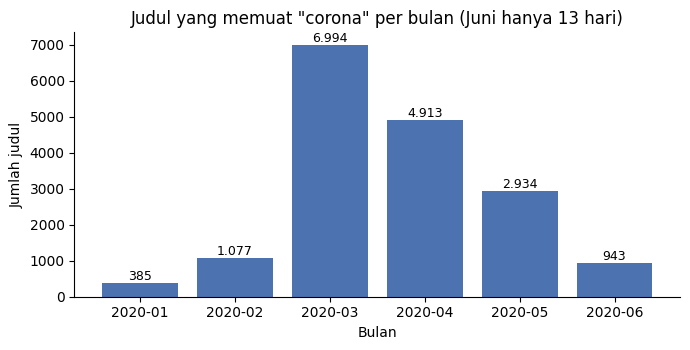

In [31]:
import matplotlib.pyplot as plt

# (a) Kapan topik corona memuncak: jumlah dan porsi judul per bulan
per_bulan_sk = con.sql("""
    SELECT bulan, COUNT(*) AS total_judul,
           COUNT(*) FILTER (WHERE lower(judul) LIKE '%corona%') AS judul_corona
    FROM berita GROUP BY bulan ORDER BY bulan""").df()
per_bulan_sk["porsi_corona_%"] = (per_bulan_sk["judul_corona"] / per_bulan_sk["total_judul"] * 100).round(1)
print(per_bulan_sk.to_string(index=False))

# (b) Kategori yang paling banyak membahas corona
per_kat_sk = con.sql("""
    SELECT kategori, COUNT(*) AS total_judul,
           COUNT(*) FILTER (WHERE lower(judul) LIKE '%corona%') AS judul_corona
    FROM berita GROUP BY kategori""").df()
per_kat_sk["porsi_corona_%"] = (per_kat_sk["judul_corona"] / per_kat_sk["total_judul"] * 100).round(1)
print()
print(per_kat_sk.sort_values("judul_corona", ascending=False).to_string(index=False))

# (b) Kategori yang bahasannya paling berbeda: irisan 20 kata teratas kategori dengan 20 kata teratas seluruh data
top20_semua = {k for k, _ in top[:20]}
irisan = []
for kat in sorted(per_kategori):
    top20_kat = {k for _, k in sorted(per_kategori[kat], reverse=True)[:20]}
    irisan.append({"kategori": kat, "kata sama dengan 20 besar umum": len(top20_kat & top20_semua),
                   "contoh kata khas": ", ".join(sorted(top20_kat - top20_semua)[:6])})
irisan = pd.DataFrame(irisan).sort_values("kata sama dengan 20 besar umum")
print()
print(irisan.to_string(index=False))

# Grafik untuk laporan
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(per_bulan_sk["bulan"], per_bulan_sk["judul_corona"], color="#4C72B0")
for x, y in zip(per_bulan_sk["bulan"], per_bulan_sk["judul_corona"]):
    ax.text(x, y, f"{y:,}".replace(",", "."), ha="center", va="bottom", fontsize=9)
ax.set_title('Judul yang memuat "corona" per bulan (Juni hanya 13 hari)')
ax.set_xlabel("Bulan"); ax.set_ylabel("Jumlah judul")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(SIAP / "corona_per_bulan.png", dpi=150)
plt.show()

```markdown
## Tugas Mandiri: Inverted Index dengan MapReduce
Kolom `id` kosong untuk seluruh kategori inet. Baris inet tidak dibuang (agar judulnya tetap bisa dicari);
sebagai gantinya dibuat id pengganti yang tetap dari isi judul: `inet-<crc32 judul>`. Id ini selalu sama setiap kali dijalankan
(tidak bergantung pada urutan baris) dan diberi awalan `inet-` agar tidak tertukar dengan id asli detik.
Stopword tidak diindeks karena hampir setiap judul memuatnya.
```

## Tugas Mandiri: Inverted Index dengan MapReduce
Kolom `id` kosong untuk seluruh kategori inet. Baris inet tidak dibuang (agar judulnya tetap bisa dicari);
sebagai gantinya dibuat id pengganti yang tetap dari isi judul: `inet-<crc32 judul>`. Id ini selalu sama setiap kali dijalankan
(tidak bergantung pada urutan baris) dan diberi awalan `inet-` agar tidak tertukar dengan id asli detik.
Stopword tidak diindeks karena hampir setiap judul memuatnya.

In [32]:
def id_dokumen(id_asli, judul):
    """Id asli detik bila ada; bila kosong (kategori inet), id pengganti dari CRC32 judul."""
    if pd.notna(id_asli):
        return str(int(id_asli))
    return f"inet-{zlib.crc32(judul.encode()):08x}"

def mapper_indeks(path):
    """Satu split -> pasangan (kata, id); satu kata dihitung sekali per judul."""
    df_ = pd.read_parquet(path, columns=["judul", "id"])
    pasangan = []
    for i, t in zip(df_["id"], df_["judul"]):
        d = id_dokumen(i, t)
        for kata in sorted(set(tokenisasi(t)) - STOPWORD):
            pasangan.append((kata, d))
    return pasangan

def urut_id(d):
    return (1, d) if d.startswith("inet-") else (0, int(d))

def reducer_indeks(kata, daftar_id):
    """Gabungkan id menjadi daftar terurut tanpa duplikat."""
    return kata, sorted(set(daftar_id), key=urut_id)

# MAP
map_indeks = [mapper_indeks(p) for p in splits]
# SHUFFLE
shuffle_indeks = collections.defaultdict(list)
for h in map_indeks:
    for kata, d in h:
        shuffle_indeks[kata].append(d)
# REDUCE
indeks_terbalik = dict(reducer_indeks(k, v) for k, v in shuffle_indeks.items())

# Pemeriksaan id pengganti: harus unik
semua_id = [id_dokumen(i, t) for i, t in zip(bersih["id"], bersih["judul"])]
print("Dokumen (judul)            :", f"{len(semua_id):,}")
print("Id unik                    :", f"{len(set(semua_id)):,}", "| bentrok:", len(semua_id) - len(set(semua_id)))
print("Id pengganti (inet)        :", f"{sum(d.startswith('inet-') for d in semua_id):,}")
print("Pasangan (kata, id)        :", f"{sum(len(h) for h in map_indeks):,}")
print("Kata dalam indeks          :", f"{len(indeks_terbalik):,}")

# Tiga kata contoh beserta lima id pertamanya, dicek silang dengan pencarian langsung
print()
for kata in ["corona", "jokowi", "mudik"]:
    daftar = indeks_terbalik.get(kata, [])
    langsung = {id_dokumen(i, t) for i, t in zip(bersih["id"], bersih["judul"]) if kata in tokenisasi(t)}
    print(f"{kata:<8} {len(daftar):>6,} dokumen | 5 id pertama: {daftar[:5]} | sama dengan pencarian langsung: {set(daftar) == langsung}")
contoh_inet = next(k for k, v in indeks_terbalik.items() if any(d.startswith("inet-") for d in v) and len(v) > 50)
print(f"\nContoh kata yang memuat id inet: {contoh_inet} -> {[d for d in indeks_terbalik[contoh_inet] if d.startswith('inet-')][:3]}")

# Simpan ke siap_pakai/ (Parquet dan database laporan)
indeks_df = pd.DataFrame({"kata": list(indeks_terbalik),
                          "jumlah_dokumen": [len(v) for v in indeks_terbalik.values()],
                          "daftar_id": [json.dumps(v) for v in indeks_terbalik.values()]})
indeks_df.to_parquet(SIAP / "inverted_index.parquet", index=False)
db = sqlite3.connect(SIAP / "laporan.db")
indeks_df.to_sql("inverted_index", db, if_exists="replace", index=False)
print("Baris indeks diekspor:", db.execute("SELECT COUNT(*) FROM inverted_index").fetchone()[0])
print(db.execute("SELECT kata, jumlah_dokumen FROM inverted_index ORDER BY jumlah_dokumen DESC LIMIT 5").fetchall())
db.close()

Dokumen (judul)            : 90,818
Id unik                    : 90,818 | bentrok: 0
Id pengganti (inet)        : 5,577
Pasangan (kata, id)        : 704,032
Kata dalam indeks          : 32,228

corona   17,228 dokumen | 5 id pertama: ['4856495', '4856598', '4868317', '4868545', '4869163'] | sama dengan pencarian langsung: True
jokowi    2,316 dokumen | 5 id pertama: ['4842674', '4842690', '4842703', '4842774', '4843215'] | sama dengan pencarian langsung: True
mudik       888 dokumen | 5 id pertama: ['4852294', '4853938', '4856814', '4856929', '4857196'] | sama dengan pencarian langsung: True

Contoh kata yang memuat id inet: awasi -> ['inet-4ccec8cc', 'inet-57fa1e7e', 'inet-6304dd0a']
Baris indeks diekspor: 32228
[('corona', 17228), ('rp', 3094), ('virus', 3067), ('polisi', 2724), ('kasus', 2692)]


```markdown
## Pengumpulan: Zip Folder Lapisan Data
Berkas di Colab hilang saat sesi berakhir, jadi zip disimpan ke Google Drive (folder `BigData/Praktikum5`).
```

## Pengumpulan: Zip Folder Lapisan Data
Berkas di Colab hilang saat sesi berakhir, jadi zip disimpan ke Google Drive (folder `BigData/Praktikum5`).

In [33]:
from google.colab import drive
drive.mount("/content/drive")
DIR_SIMPAN = Path("/content/drive/MyDrive/BigData/Praktikum5"); DIR_SIMPAN.mkdir(parents=True, exist_ok=True)

for folder in ["lapisan_mentah", "lapisan_terkurasi", "siap_pakai", "contoh_crawl"]:
    if Path(folder).exists():
        arsip = shutil.make_archive(str(DIR_SIMPAN / folder), "zip", root_dir=".", base_dir=folder)
        print(f"{folder:<18} -> {Path(arsip).name:<24} {Path(arsip).stat().st_size / 1e6:6.1f} MB")
for berkas in ["hasil_pipe.txt", "mapper.py", "reducer.py"]:
    shutil.copy(berkas, DIR_SIMPAN / berkas)
print("\nIsi folder Drive:", sorted(p.name for p in DIR_SIMPAN.iterdir()))

Mounted at /content/drive
lapisan_mentah     -> lapisan_mentah.zip          5.1 MB
lapisan_terkurasi  -> lapisan_terkurasi.zip       7.2 MB
siap_pakai         -> siap_pakai.zip              8.0 MB
contoh_crawl       -> contoh_crawl.zip            0.0 MB

Isi folder Drive: ['contoh_crawl.zip', 'hasil_pipe.txt', 'lapisan_mentah.zip', 'lapisan_terkurasi.zip', 'mapper.py', 'reducer.py', 'siap_pakai.zip']
